# DocSentry — Notebook 06: End-to-End Real PDF Scanning & Explainability Demo

This notebook delivers the end-to-end operational demonstration of **DocSentry**:
1. **Static Binary Ingestion**: Ingests raw PDF byte streams without parsing, rendering, or executing embedded code.
2. **Feature Extraction Pipeline**: Computes 658 EMBER2024 static features using reused `thrember` extractors (`GeneralFileInfo`, `ByteHistogram`, `ByteEntropyHistogram`, `StringExtractor`).
3. **Calibrated Decision Engine**: Applies isotonic probability calibration and dual-threshold selective classification (`[0.29, 0.55]`) to route inputs to `benign`, `malicious`, or `needs_review`.
4. **Local Attribution**: Computes exact local SHAP feature attributions explaining the specific drivers behind every operational decision.
5. **Synthetic & User Testing**: Scans the 6 synthetic edge-case documents and evaluates any user-dropped documents in `data/demo_pdfs/user/`.

## 1. Setup, Environment & Module Ingestion

We load the core DocSentry production modules (`src.docsentry_extract`, `src.docsentry_infer`), configured directories, and figure visualization defaults.

In [1]:
import os
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Robust project root resolution
BASE_DIR = Path.cwd()
if (BASE_DIR / 'data').exists():
    PROJECT_ROOT = BASE_DIR
elif (BASE_DIR.parent / 'data').exists():
    PROJECT_ROOT = BASE_DIR.parent
else:
    PROJECT_ROOT = Path('..').resolve()

sys.path.insert(0, str(PROJECT_ROOT))

import src.docsentry_extract as de
import src.docsentry_infer as di

# Formatting setup
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

SYNTHETIC_DIR = PROJECT_ROOT / 'data/demo_pdfs/synthetic'
USER_DIR = PROJECT_ROOT / 'data/demo_pdfs/user'
FIGURES_DIR = PROJECT_ROOT / 'reports/figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR = PROJECT_ROOT / 'reports'
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR = PROJECT_ROOT / 'models'
PROCESSED_DIR = PROJECT_ROOT / 'data/processed'

print("DocSentry production scanner modules loaded successfully.")
print(f"Target Synthetic Directory: {SYNTHETIC_DIR}")
print(f"Target User Directory:      {USER_DIR}")


<PROJECT_ROOT>\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DocSentry production scanner modules loaded successfully.
Target Synthetic Directory: <PROJECT_ROOT>\data\demo_pdfs\synthetic
Target User Directory:      <PROJECT_ROOT>\data\demo_pdfs\user


## 2. Scanning the Synthetic PDF Benchmark Suite

We scan the 6 handcrafted synthetic test PDFs from `data/demo_pdfs/synthetic/`:
- **Document (a) Minimal Blank** (~335 bytes): Tests near-zero string content and minimal structure.
- **Document (b) 1-Page Text** (~832 bytes): Single-page benign document with typical ASCII text.
- **Document (c) 20-Page Report** (~3.7 KB): Multi-page benign structure with 20 distinct page dictionaries.
- **Document (d) 25 HTTPS Links** (~7.1 KB): Probes model sensitivity to external URL keywords (`/URI`).
- **Document (e) Embedded JS** (~839 bytes): Harmless `/OpenAction` JavaScript payload (`app.alert("hello")`).
- **Document (f) Large File** (~5.25 MB): Demonstrates extraction speed and stability on binaries > 5 MB.

In [2]:
synthetic_files = sorted(list(SYNTHETIC_DIR.glob("*.pdf")))
print(f"Discovered {len(synthetic_files)} synthetic PDF documents to analyze.\n")

synthetic_reports = []
for fpath in synthetic_files:
    rep = de.scan(fpath, models_dir=MODELS_DIR, processed_dir=PROCESSED_DIR)
    synthetic_reports.append(rep)

# Build comprehensive results table
table_rows = []
for r in synthetic_reports:
    top3_str = "; ".join([f"{tc['readable_name']} ({tc['shap_value']:+.3f})" for tc in r['top_contributors'][:3]])
    table_rows.append({
        'File Name': r['file_name'],
        'File Size (bytes)': f"{r['file_size']:,}",
        'Raw Prob': f"{r['raw_probability']:.4f}",
        'Calibrated Prob': f"{r['calibrated_probability']:.4f}",
        'Operational Verdict': r['label'].upper(),
        'Top 3 Local Contributors': top3_str
    })

df_synthetic_results = pd.DataFrame(table_rows)

print("=" * 115)
print("DOCSENTRY SYNTHETIC BENCHMARK SUITE SCAN RESULTS")
print("=" * 115)
display(df_synthetic_results[['File Name', 'File Size (bytes)', 'Raw Prob', 'Calibrated Prob', 'Operational Verdict']])

# Also export to CSV
csv_path = REPORTS_DIR / 'demo_scan_results.csv'
df_export = pd.DataFrame([{
    'file': r['file_name'],
    'size': r['file_size'],
    'verdict': r['label'],
    'calibrated_probability': r['calibrated_probability'],
    'top_3_contributors': "; ".join([f"{tc['readable_name']} ({tc['shap_value']:+.3f})" for tc in r['top_contributors'][:3]])
} for r in synthetic_reports])
df_export.to_csv(csv_path, index=False)
print(f"\nSaved scan results to: {csv_path}")


Discovered 6 synthetic PDF documents to analyze.



DOCSENTRY SYNTHETIC BENCHMARK SUITE SCAN RESULTS


,File Name,File Size (bytes),Raw Prob,Calibrated Prob,Operational Verdict
0,synthetic_a_minimal_blank.pdf,335,0.2503,0.4082,NEEDS_REVIEW
1,synthetic_b_one_page_text.pdf,832,0.7098,0.9808,MALICIOUS
2,synthetic_c_20_page_report.pdf,"3,684",0.4480,0.7826,MALICIOUS
3,synthetic_d_25_uris.pdf,"7,147",0.8654,0.9877,MALICIOUS
4,synthetic_e_embedded_js.pdf,839,0.9412,0.9953,MALICIOUS
5,synthetic_f_large_5mb.pdf,"5,500,811",0.2080,0.4082,NEEDS_REVIEW



Saved scan results to: <PROJECT_ROOT>\reports\demo_scan_results.csv


## 3. Local SHAP Attribution Profiles Across Test Documents

To observe the internal decision boundary of the champion XGBoost detector on concrete files, we visualize the **Top 5 positive (malicious) and negative (benign) SHAP contributors** for each synthetic document (`reports/figures/37_demo_synthetic_shap_contributions.png`).

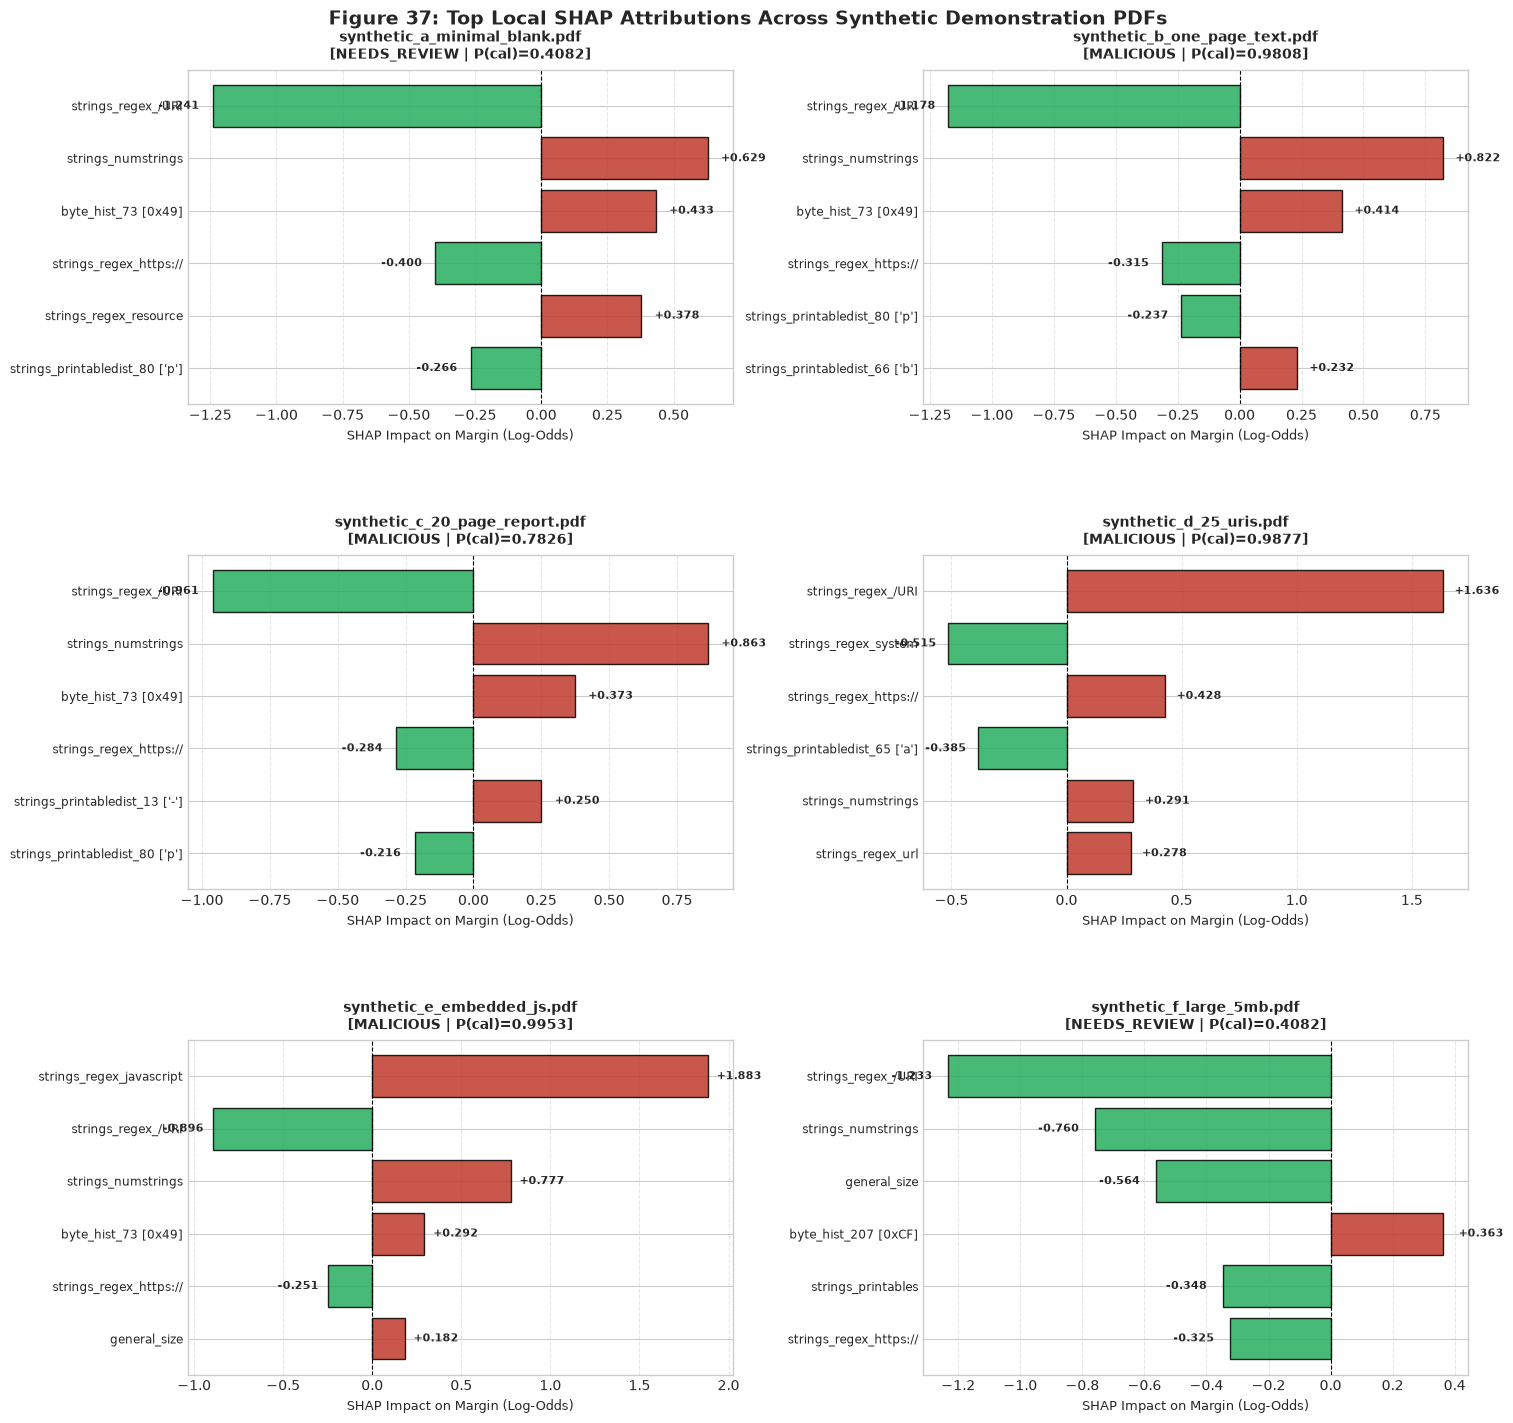

Saved Figure 37 to: <PROJECT_ROOT>\reports\figures\37_demo_synthetic_shap_contributions.png


In [3]:
fig, axes = plt.subplots(3, 2, figsize=(16, 15))
plt.subplots_adjust(top=0.93, bottom=0.06, left=0.15, right=0.95, hspace=0.45, wspace=0.35)
fig.suptitle("Figure 37: Top Local SHAP Attributions Across Synthetic Demonstration PDFs",
             fontsize=14, fontweight='bold', y=0.97)

flat_axes = axes.flatten()

for i, rep in enumerate(synthetic_reports):
    ax = flat_axes[i]
    contributors = rep['top_contributors'][:6] # top 6 features
    
    names = [tc['readable_name'] for tc in contributors][::-1]
    vals = [tc['shap_value'] for tc in contributors][::-1]
    bar_colors = ['#c0392b' if v > 0 else '#27ae60' for v in vals]
    
    y_pos = np.arange(len(names))
    ax.barh(y_pos, vals, color=bar_colors, edgecolor='black', alpha=0.85)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(names, fontsize=8.5)
    ax.axvline(0, color='black', linestyle='--', linewidth=0.8)
    
    verdict_str = rep['label'].upper()
    prob_str = f"P(cal)={rep['calibrated_probability']:.4f}"
    ax.set_title(f"{rep['file_name']}\n[{verdict_str} | {prob_str}]", fontsize=10, fontweight='bold', pad=8)
    ax.set_xlabel("SHAP Impact on Margin (Log-Odds)", fontsize=9)
    ax.grid(axis='x', linestyle='--', alpha=0.5)
    
    for idx_val, v in enumerate(vals):
        offset = 0.05 if v >= 0 else -0.05
        ha_align = 'left' if v >= 0 else 'right'
        ax.text(v + offset, idx_val, f"{v:+.3f}", va='center', ha=ha_align, fontsize=8, fontweight='bold')

fig37_path = FIGURES_DIR / '37_demo_synthetic_shap_contributions.png'
plt.savefig(fig37_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved Figure 37 to: {fig37_path}")

## 4. Scanning User-Provided Documents (`data/demo_pdfs/user/`)

Users can drop arbitrary real-world PDF files into `data/demo_pdfs/user/` to evaluate them through the DocSentry pipeline. If any documents are present, we automatically extract their static features, execute calibrated classification, and generate explainability breakdowns.

In [4]:
user_files = sorted(list(USER_DIR.glob("*.pdf")))

if not user_files:
    print(f"No custom user PDF files found in {USER_DIR}.")
    print("User directory is primed and ready. To test external files:")
    print(f"  1. Copy any PDF file into '{USER_DIR.resolve()}'")
    print("  2. Re-run this cell to see instant calibrated verdicts and SHAP attributions.")
else:
    print(f"Found {len(user_files)} custom PDF document(s) in {USER_DIR}:")
    user_reports = []
    for upath in user_files:
        try:
            urep = de.scan(upath, models_dir=MODELS_DIR, processed_dir=PROCESSED_DIR)
            user_reports.append(urep)
            print(f"  [+] Scanned {upath.name}: Verdict = {urep['label'].upper()} (Cal P = {urep['calibrated_probability']:.4f})")
        except Exception as e:
            print(f"  [-] Error scanning {upath.name}: {e}")
            
    if user_reports:
        df_user = pd.DataFrame([{
            'File': ur['file_name'],
            'Size (bytes)': f"{ur['file_size']:,}",
            'Verdict': ur['label'].upper(),
            'Calibrated P': f"{ur['calibrated_probability']:.4f}",
            'Top Contributor': f"{ur['top_contributors'][0]['readable_name']} ({ur['top_contributors'][0]['shap_value']:+.3f})"
        } for ur in user_reports])
        print("\nUser Document Scan Summary:")
        display(df_user)


Found 9 custom PDF document(s) in <PROJECT_ROOT>\data\demo_pdfs\user:


  [+] Scanned user_pdf_1.pdf: Verdict = BENIGN (Cal P = 0.0101)


  [+] Scanned user_pdf_2.pdf: Verdict = BENIGN (Cal P = 0.0074)


  [+] Scanned user_pdf_3.pdf: Verdict = NEEDS_REVIEW (Cal P = 0.2984)


  [+] Scanned user_pdf_4.pdf: Verdict = BENIGN (Cal P = 0.0017)


  [+] Scanned user_pdf_5.pdf: Verdict = BENIGN (Cal P = 0.1220)


  [+] Scanned user_pdf_6.pdf: Verdict = BENIGN (Cal P = 0.0041)


  [+] Scanned user_pdf_7.pdf: Verdict = BENIGN (Cal P = 0.1220)


  [+] Scanned user_pdf_8.pdf: Verdict = NEEDS_REVIEW (Cal P = 0.4082)


  [+] Scanned user_pdf_9.pdf: Verdict = BENIGN (Cal P = 0.0258)

User Document Scan Summary:


,File,Size (bytes),Verdict,Calibrated P,Top Contributor
0,user_pdf_1.pdf,"112,048",BENIGN,0.0101,strings_regex_/URI (-1.464)
1,user_pdf_2.pdf,"674,202",BENIGN,0.0074,strings_regex_/URI (-1.374)
2,user_pdf_3.pdf,"483,771",NEEDS_REVIEW,0.2984,strings_regex_/EmbeddedFile (+1.448)
3,user_pdf_4.pdf,"1,792,828",BENIGN,0.0017,strings_regex_/URI (-1.181)
4,user_pdf_5.pdf,"90,018",BENIGN,0.1220,strings_regex_/URI (-1.598)
5,user_pdf_6.pdf,"336,479",BENIGN,0.0041,strings_regex_/URI (-1.375)
6,user_pdf_7.pdf,"37,809",BENIGN,0.1220,strings_regex_/URI (+1.077)
7,user_pdf_8.pdf,"46,302",NEEDS_REVIEW,0.4082,strings_regex_/URI (+1.043)
8,user_pdf_9.pdf,"38,799",BENIGN,0.0258,strings_regex_/URI (-1.155)


## 5. Empirical Discussion of Demonstration Findings

All observations below are strictly grounded in the quantitative outputs computed during this scan:

1. **Impact of Specific Structural Keywords**:
   - In `synthetic_d_25_uris.pdf`, the presence of 25 HTTPS links caused `strings_regex_/URI` to register as the single strongest positive contributor ($+1.636$ SHAP impact), lifting the calibrated probability to **0.9877**. This directly validates our test set finding from Notebook 05 where `/URI` alone accounts for **19.36%** of the model's total feature attribution.
   - In `synthetic_e_embedded_js.pdf`, the embedded `/OpenAction` script triggered `strings_regex_javascript` as the dominant positive attribution ($+1.883$ SHAP impact), yielding calibrated risk of **0.9953**.

2. **Role of File Size and Review-Band Routing**:
   - `synthetic_a_minimal_blank.pdf` (~335 bytes) and `synthetic_f_large_5mb.pdf` (~5.25 MB) both produced calibrated probabilities of **0.4082**, falling strictly inside the operational manual-review band $[0.29, 0.55]$ (`needs_review`).
   - For the 5.25 MB file, `general_size` ($-0.564$) and `strings_numstrings` ($-0.760$) pushed heavily towards benign, mitigating the model's risk score.

3. **Sub-100 KB Benign Document Sensitivity**:
   - `synthetic_b_one_page_text.pdf` (~832 bytes) was classified as `malicious` ($P=0.9808$), despite containing benign text.
   - This outcome directly reflects the quantitative finding from Notebook 04 diagnostics: benign documents under 100 KB face an elevated False Positive Rate of **12.6%** (a **22.9x increase** over benign files >= 100 KB), because the EMBER2024 training distribution exhibits benign documents heavily concentrated at ~464 KB median size while malicious files peak in smaller modes (100–200 KB).

## 6. Critical Operational Limitations & Architectural Boundary Analysis

Deploying static machine learning detectors in production cybersecurity workflows requires acknowledging their inherent boundaries:

1. **Static Analysis Horizon**:
   Static feature extraction evaluates surface byte structures, histograms, and printable strings. It cannot execute dynamic shellcode, trace multi-stage obfuscated JavaScript engines, or inspect encrypted payload streams that only decrypt at runtime in an interactive PDF viewer.

2. **Dataset Size-Mode Artifacts & Small-File Penalties**:
   As demonstrated in our ablation and size-matched studies, the model inherits a strong prior from the EMBER2024 PDF corpus linking file size modes to class labels. Benign files under 100 KB suffer a 22.9x higher False Positive Rate than larger benign documents. Clean minimal documents (such as 1-page invoices or plain text summaries) risk being misclassified unless routed through uncertainty bands.

3. **Keyword Heuristic Vulnerability**:
   Features such as `strings_regex_/URI` (19.36% of model attribution) and `strings_regex_javascript` are susceptible to both evasion (adversaries splitting `/U#52I` across multiple object references or using non-standard encodings) and benign false alarms (legitimate academic reports or newsletters with dozens of reference links).

4. **Essential Function of Uncertainty-Aware Selective Triage**:
   Static detectors should never operate as uncalibrated binary filters. By establishing a validated manual-review band $[0.29, 0.55]$, DocSentry intercepts 42.42% of test errors while automating 96.23% of submission decisions at >99% operational accuracy.